# 04 — Exploratory Data Analysis
**Owner:** Dev A | **Task:** T4.1  
Explore `transactions_merged.csv` to understand fraud patterns before modeling.

> **Rule:** always show **counts beside rates**. A 10% fraud rate in a bin of 50 rows is very different from 10% in 10,000 rows.

Findings from this notebook inform:
- `docs/split_strategy.md` (chronological split ✅ confirmed)
- `docs/features.md` (which raw columns are predictive)
- `src/features.py` (feature definitions)
- Dashboard charts (Dev E builds from these same observations)

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

df = pd.read_csv('../data/processed/transactions_merged.csv',
                 parse_dates=['signup_time', 'purchase_time'])
print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}  |  Fraud rate: {df["class"].mean():.2%}')

Rows: 151,112  |  Columns: 24  |  Fraud rate: 9.36%


---
## 1. Class balance

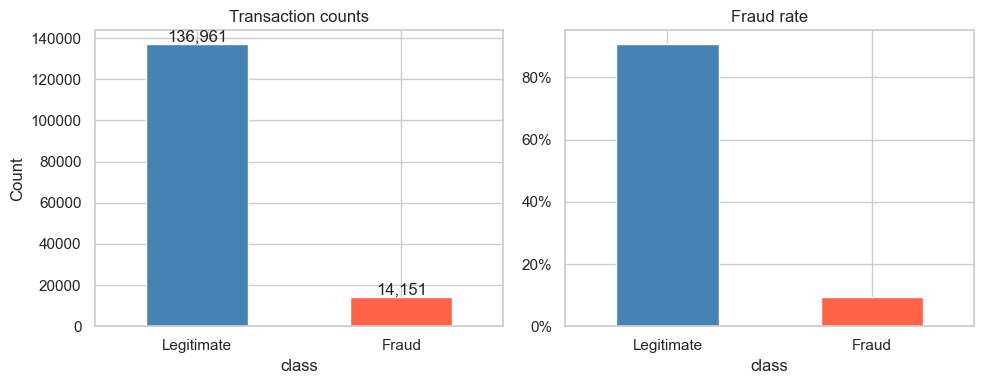

class
Legitimate    136961
Fraud          14151
class
Legitimate    90.64%
Fraud          9.36%


In [2]:
counts = df['class'].value_counts().rename({0: 'Legitimate', 1: 'Fraud'})
rates  = counts / counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
counts.plot.bar(ax=axes[0], color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Transaction counts'); axes[0].set_ylabel('Count'); axes[0].set_xticklabels(counts.index, rotation=0)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')

rates.plot.bar(ax=axes[1], color=['steelblue', 'tomato'], edgecolor='white')
axes[1].set_title('Fraud rate'); axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
axes[1].set_xticklabels(counts.index, rotation=0)
plt.tight_layout(); plt.show()

print(counts.to_string()); print(rates.map('{:.2%}'.format).to_string())

---
## 2. Time patterns — fraud rate over time

C:\Users\asus\AppData\Local\Temp\ipykernel_20944\2043239760.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['month'] = df['purchase_time'].dt.to_period('M').astype(str)


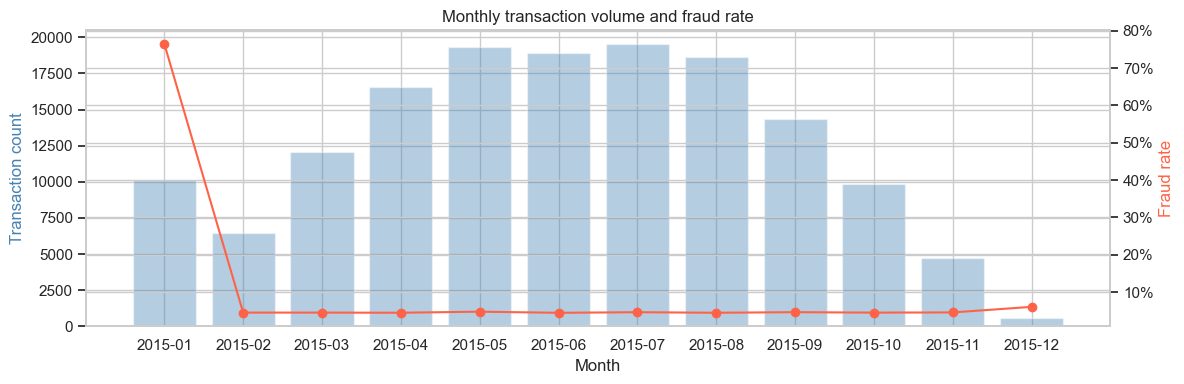

         fraud  total      rate
month                          
2015-01   7723  10097  0.764881
2015-02    291   6449  0.045123
2015-03    545  12090  0.045079
2015-04    740  16551  0.044710
2015-05    921  19364  0.047562
2015-06    842  18908  0.044531
2015-07    900  19507  0.046137
2015-08    833  18662  0.044636
2015-09    663  14347  0.046212
2015-10    442   9815  0.045033
2015-11    216   4743  0.045541
2015-12     35    579  0.060449


In [3]:
df['month'] = df['purchase_time'].dt.to_period('M').astype(str)
monthly = df.groupby('month')['class'].agg(['sum', 'count']).rename(columns={'sum': 'fraud', 'count': 'total'})
monthly['rate'] = monthly['fraud'] / monthly['total']

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()
ax1.bar(monthly.index, monthly['total'], color='steelblue', alpha=0.4, label='Total')
ax2.plot(monthly.index, monthly['rate'], 'o-', color='tomato', label='Fraud rate')
ax1.set_xlabel('Month'); ax1.set_ylabel('Transaction count', color='steelblue')
ax2.set_ylabel('Fraud rate', color='tomato')
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.title('Monthly transaction volume and fraud rate')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

print(monthly.to_string())

---
## 3. Signup-to-purchase gap

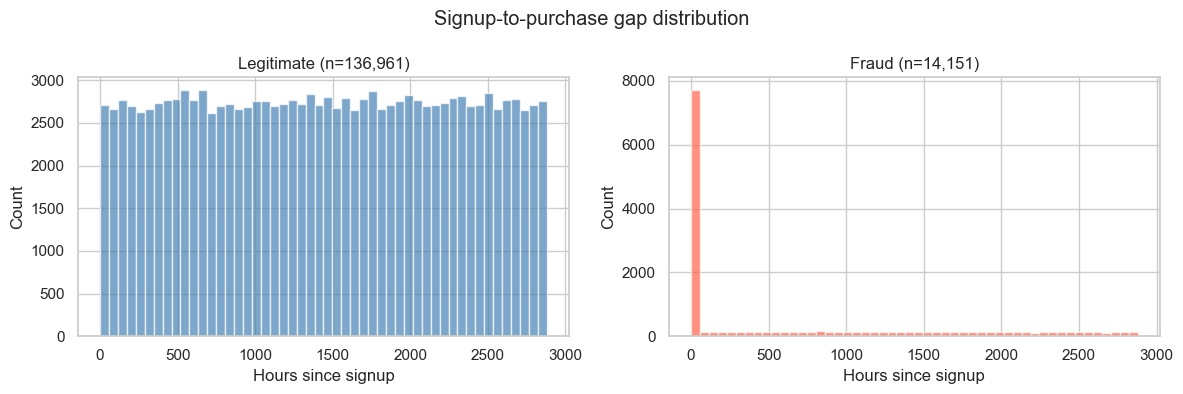

          count          mean           std    min        25%        50%  \
class                                                                      
0      136961.0  5.191179e+06  2.988589e+06  137.0  2588829.0  5194911.0   
1       14151.0  2.423842e+06  3.313789e+06    1.0        1.0        1.0   

             75%         max  
class                         
0      7781319.0  10367972.0  
1      4790510.5  10363947.0  


In [4]:
df['seconds_since_signup'] = (df['purchase_time'] - df['signup_time']).dt.total_seconds().clip(lower=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, subset in zip(axes, ['Legitimate', 'Fraud'], [df[df['class']==0], df[df['class']==1]]):
    ax.hist(subset['seconds_since_signup'] / 3600, bins=50, color='steelblue' if label=='Legitimate' else 'tomato', alpha=0.7)
    ax.set_title(f'{label} (n={len(subset):,})')
    ax.set_xlabel('Hours since signup'); ax.set_ylabel('Count')
plt.suptitle('Signup-to-purchase gap distribution'); plt.tight_layout(); plt.show()

print(df.groupby('class')['seconds_since_signup'].describe())

---
## 4. Hour of day and day of week

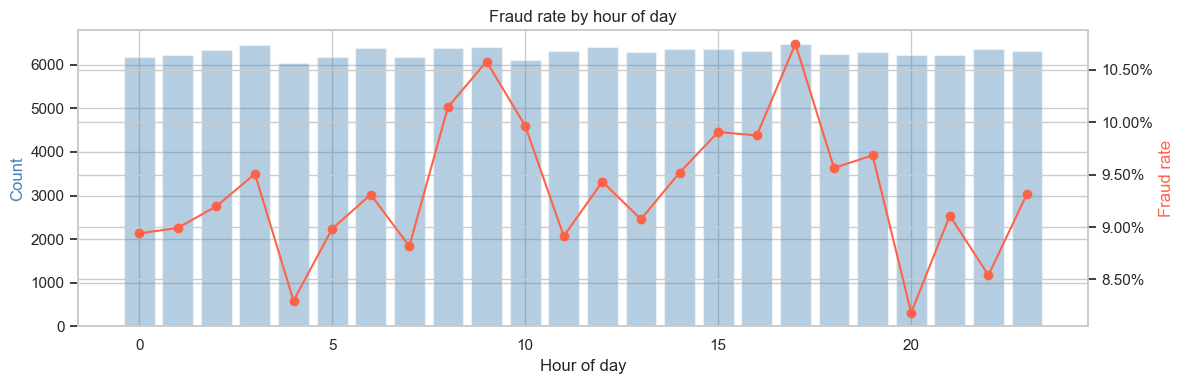

In [5]:
df['hour'] = df['purchase_time'].dt.hour
df['dow']  = df['purchase_time'].dt.day_name()

hour_stats = df.groupby('hour')['class'].agg(['sum', 'count']).rename(columns={'sum':'fraud','count':'total'})
hour_stats['rate'] = hour_stats['fraud'] / hour_stats['total']

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()
ax1.bar(hour_stats.index, hour_stats['total'], color='steelblue', alpha=0.4)
ax2.plot(hour_stats.index, hour_stats['rate'], 'o-', color='tomato')
ax1.set_xlabel('Hour of day'); ax1.set_ylabel('Count', color='steelblue')
ax2.set_ylabel('Fraud rate', color='tomato')
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.title('Fraud rate by hour of day'); plt.tight_layout(); plt.show()

---
## 5. Browser and source


--- browser ---
         fraud  total      rate
browser                        
Chrome    6069  61432  0.098792
Firefox   2342  24610  0.095165
Safari    2225  24667  0.090201
Opera      328   3676  0.089227
Ie        3187  36727  0.086775


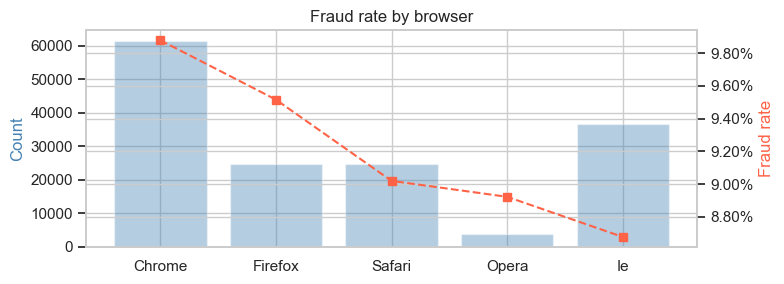


--- source ---
        fraud  total      rate
source                        
Direct   3226  30616  0.105370
Ads      5513  59881  0.092066
Seo      5412  60615  0.089285


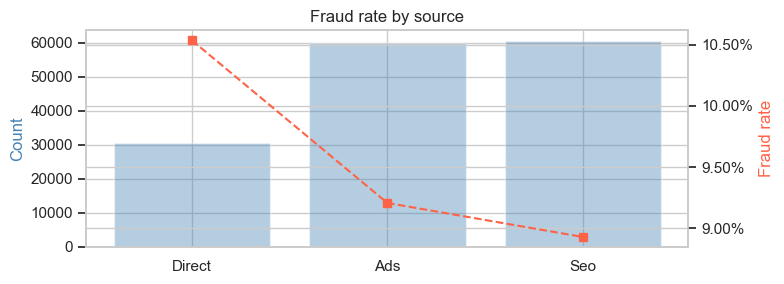


--- sex ---
     fraud  total      rate
sex                        
M     8434  88293  0.095523
F     5717  62819  0.091007


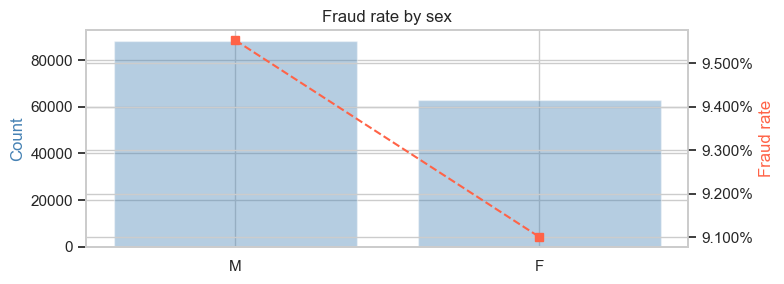

In [6]:
def fraud_by_cat(col):
    g = df.groupby(col)['class'].agg(['sum','count']).rename(columns={'sum':'fraud','count':'total'})
    g['rate'] = g['fraud'] / g['total']
    return g.sort_values('rate', ascending=False)

for col in ['browser', 'source', 'sex']:
    g = fraud_by_cat(col)
    print(f'\n--- {col} ---')
    print(g.to_string())

    fig, ax1 = plt.subplots(figsize=(8, 3))
    ax2 = ax1.twinx()
    ax1.bar(g.index, g['total'], color='steelblue', alpha=0.4)
    ax2.plot(g.index, g['rate'], 's--', color='tomato')
    ax1.set_ylabel('Count', color='steelblue')
    ax2.set_ylabel('Fraud rate', color='tomato')
    ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    plt.title(f'Fraud rate by {col}'); plt.tight_layout(); plt.show()

---
## 6. Country (top 15 by volume)

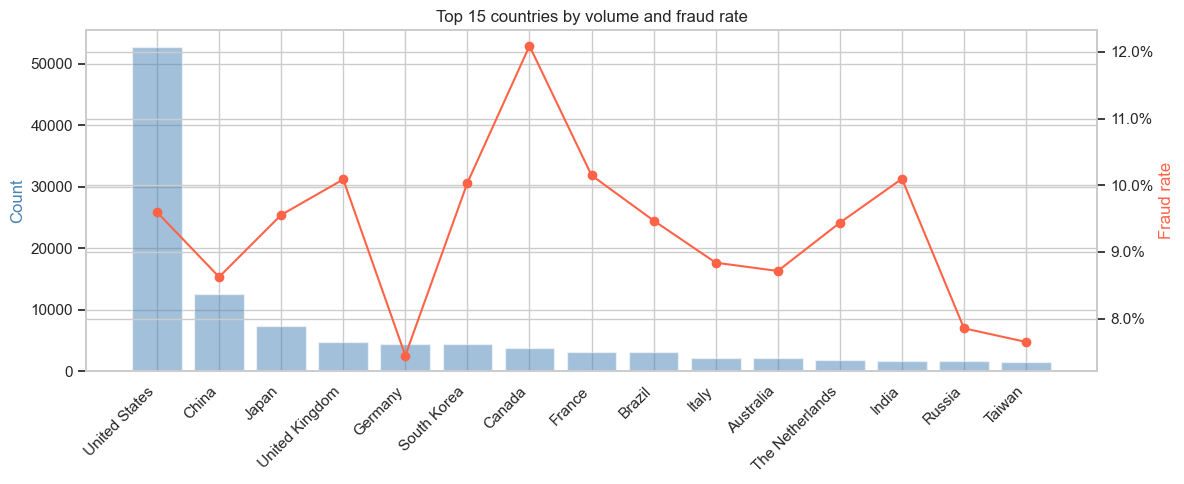

                 fraud  total      rate
country                                
United States     5064  52768  0.095967
China             1086  12592  0.086245
Japan              699   7315  0.095557
United Kingdom     471   4669  0.100878
Germany            326   4378  0.074463
South Korea        437   4354  0.100367
Canada             443   3664  0.120906
France             321   3163  0.101486
Brazil             286   3020  0.094702
Italy              188   2127  0.088387
Australia          181   2077  0.087145
The Netherlands    173   1833  0.094381
India              166   1644  0.100973
Russia             123   1566  0.078544
Taiwan             110   1438  0.076495


In [7]:
g = df.groupby('country')['class'].agg(['sum','count']).rename(columns={'sum':'fraud','count':'total'})
g['rate'] = g['fraud'] / g['total']
top15 = g.nlargest(15, 'total')

fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(top15))
ax.bar(x, top15['total'], color='steelblue', alpha=0.5, label='Total')
ax2 = ax.twinx()
ax2.plot(x, top15['rate'], 'o-', color='tomato', label='Fraud rate')
ax.set_xticks(list(x)); ax.set_xticklabels(top15.index, rotation=45, ha='right')
ax.set_ylabel('Count', color='steelblue'); ax2.set_ylabel('Fraud rate', color='tomato')
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.title('Top 15 countries by volume and fraud rate'); plt.tight_layout(); plt.show()

print(top15.to_string())

---
## 7. IP features — proxy and hosting

In [8]:
for col in ['proxy', 'hosting']:
    g = df.groupby(col)['class'].agg(['sum','count']).rename(columns={'sum':'fraud','count':'total'})
    g['rate'] = g['fraud'] / g['total']
    print(f'\n--- {col} ---')
    print(g.to_string())


--- proxy ---
       fraud   total      rate
proxy                         
0      14068  150323  0.093585
1         83     789  0.105196

--- hosting ---
         fraud   total      rate
hosting                         
0        12940  137294  0.094250
1         1211   13818  0.087639


---
## 8. CPI score distribution

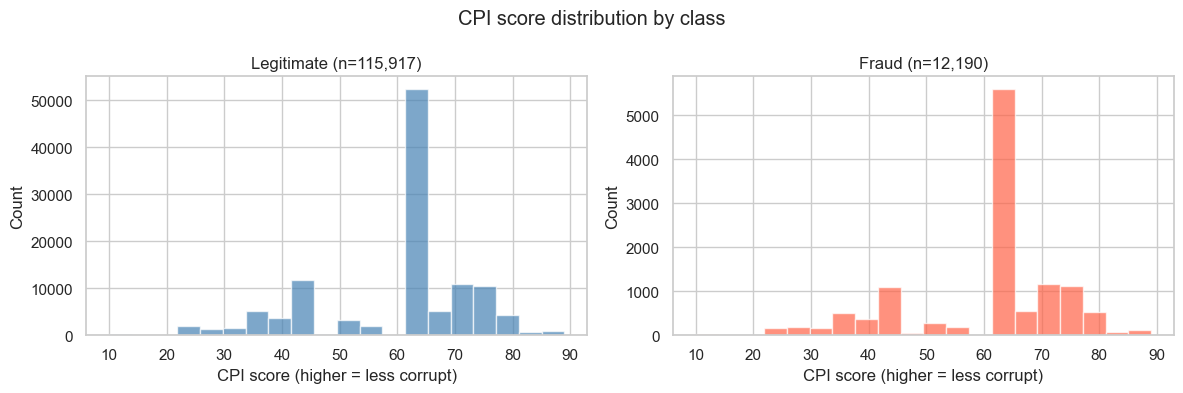

In [9]:
cpi_matched = df[df['cpi_matched'] == True]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, subset in zip(axes, ['Legitimate', 'Fraud'],
                              [cpi_matched[cpi_matched['class']==0],
                               cpi_matched[cpi_matched['class']==1]]):
    ax.hist(subset['cpi_score'], bins=20, color='steelblue' if label=='Legitimate' else 'tomato', alpha=0.7)
    ax.set_title(f'{label} (n={len(subset):,})')
    ax.set_xlabel('CPI score (higher = less corrupt)'); ax.set_ylabel('Count')
plt.suptitle('CPI score distribution by class'); plt.tight_layout(); plt.show()

---
## 9. Shared device — users per device

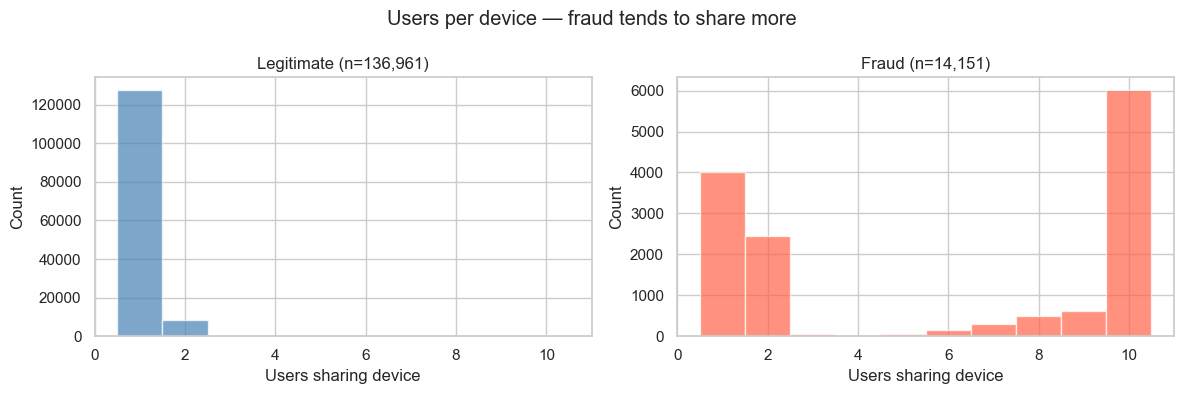

In [10]:
device_counts = df.groupby('device_id')['user_id'].nunique()
df['users_per_device_full'] = df['device_id'].map(device_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, subset in zip(axes, ['Legitimate', 'Fraud'],
                              [df[df['class']==0], df[df['class']==1]]):
    ax.hist(subset['users_per_device_full'].clip(upper=10), bins=10, range=(0.5, 10.5),
            color='steelblue' if label=='Legitimate' else 'tomato', alpha=0.7)
    ax.set_title(f'{label} (n={len(subset):,})')
    ax.set_xlabel('Users sharing device'); ax.set_ylabel('Count')
plt.suptitle('Users per device — fraud tends to share more'); plt.tight_layout(); plt.show()

---
## 10. Split sanity — fraud rate per split

Already computed when building `features.csv`. Reproduced here for the EDA record.

In [11]:
feat = pd.read_csv('../data/processed/features.csv')
split_stats = feat.groupby('split')['class'].agg(['sum','count']).rename(columns={'sum':'fraud','count':'total'})
split_stats['rate'] = split_stats['fraud'] / split_stats['total']
split_stats = split_stats.reindex(['train', 'valid', 'test'])
print(split_stats.to_string())

print('\n⚠️  Fraud rate drops from train (11.4%) to valid/test (~4.6%).')
print('   Model is calibrated on a higher-fraud regime than it is evaluated on.')
print('   See docs/split_strategy.md — threshold must be tuned on validation data.')

       fraud   total      rate
split                         
train  12077  105778  0.114173
valid   1040   22666  0.045884
test    1034   22668  0.045615

⚠️  Fraud rate drops from train (11.4%) to valid/test (~4.6%).
   Model is calibrated on a higher-fraud regime than it is evaluated on.
   See docs/split_strategy.md — threshold must be tuned on validation data.


---
## 11. Summary of EDA findings

| Finding | Implication |
|---|---|
| Fraud rate drops over time (11.4% train → 4.6% test) | Tune threshold on validation data; use PR-AUC not ROC-AUC |
| Fraud concentrates in short signup-to-purchase windows | `seconds_since_signup` is a strong feature |
| Hosting IPs have elevated fraud rate | `is_hosting` flag is a valuable feature |
| Shared devices (up to 20 users) correlate with fraud | `users_per_device` and `users_per_ip` are informative |
| Some countries have much higher fraud rates | CPI score + country encoding worth including |
| Browser and source show modest differences | Include as one-hot encoded features |
| Hour of day shows some variation | `hour_of_day` included as a feature |